# 02 · Experimentación del pronóstico de demanda (Caso A)

**Objetivo.** Pronosticar la demanda semanal de cada SKU-tienda para la semana del lunes 1 al domingo 7 de abril de 2024, con una medida de incertidumbre que sirva para decidir el pedido.

**Qué se hace aquí.** El EDA (`01_EDA_abastecimiento_tostao.ipynb`) decidió *qué variables entran* y *qué referencias hay que superar*. Este notebook pone esas decisiones a prueba de forma ordenada, siempre fuera de muestra:

1. Cargar, validar y construir las variables sin mirar el futuro.
2. Comparar modelos con el mismo backtest de origen móvil (semanas 6 a 13).
3. Revisar sensibilidad a hiperparámetros y a la pérdida del modelo.
4. Ver dónde falla el pronóstico (día, producto, volumen).
5. Calibrar los cuantiles y comprobar su cobertura fuera de muestra.
6. Generar el pronóstico de la semana 1–7 de abril.

**Cómo leerlo.** El código vive en `src/tostao_abastecimiento/`; aquí solo se llama y se interpreta. Las decisiones se imprimen con reglas explícitas al final de cada sección, no se asumen.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
if "DATA_DIR" not in globals():
    DATA_DIR = RAIZ / "data" / "01_supply_optimization"     # ver README: dónde colocar los datos

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3})

In [2]:
from tostao_abastecimiento.data import cargar_caso_a, validar_datos
from tostao_abastecimiento.features import construir_panel, dividir_historia_futuro
from tostao_abastecimiento.config import COLUMNAS_MODELO
from tostao_abastecimiento.models import (MediaCuatroSemanasMismoDia, ModeloPoissonGBM,
                                          NaiveSemanaPasada, PerfilPorNivel)
from tostao_abastecimiento.validation import (agregar_semanal, backtest_origen_movil, resumen_wape,
                                              semanas_de_prueba, wape)
from tostao_abastecimiento.calibration import CalibradorCuantiles, cobertura_secuencial
from tostao_abastecimiento.pipeline import MODELOS_BACKTEST, MODELO_FINAL, pronosticar_semana

## 1. Datos y variables

Se validan las tablas del Caso A y se arma el panel SKU-tienda-día. Cada variable de una fila usa solo información disponible hasta el domingo previo al lunes de su semana: rezagos de 7, 14, 21 y 28 días, promedio de las últimas 4 semanas del mismo día de la semana y medias móviles de 7 y 28 días evaluadas en ese domingo.

In [3]:
datos = cargar_caso_a(DATA_DIR)
problemas = validar_datos(datos)
print("Problemas de validación:", problemas or "ninguno")

panel = construir_panel(datos)
historia, futuro = dividir_historia_futuro(panel)
print(f"Panel: {len(panel):,} filas | historia: {len(historia):,} | a pronosticar: {len(futuro):,}")
print("Semanas de prueba del backtest:", semanas_de_prueba(panel))
print("Variables del modelo:", list(COLUMNAS_MODELO))
panel[panel["id_tienda"].eq(panel["id_tienda"].iloc[0]) & panel["id_producto"].eq(panel["id_producto"].iloc[0])].tail(10)

Problemas de validación: ninguno
Panel: 15,680 filas | historia: 14,560 | a pronosticar: 1,120
Semanas de prueba del backtest: [6, 7, 8, 9, 10, 11, 12, 13]
Variables del modelo: ['dow', 'tienda_cod', 'producto_cod', 'lag_7', 'lag_14', 'lag_21', 'lag_28', 'dow_mean4', 'rm7', 'rm28']


,fecha,id_tienda,id_producto,unidades_vendidas,dow,semana,tienda_cod,producto_cod,lag_7,lag_14,lag_21,lag_28,dow_mean4,fecha_asof,rm7,rm28
88,2024-03-29,STORE_01,PROD_001,9.000,4,13,0,0,5.000,10.000,4.000,8.000,6.750,2024-03-24,6.429,6.393
89,2024-03-30,STORE_01,PROD_001,10.000,5,13,0,0,10.000,12.000,6.000,11.000,9.750,2024-03-24,6.429,6.393
90,2024-03-31,STORE_01,PROD_001,6.000,6,13,0,0,11.000,4.000,9.000,9.000,8.250,2024-03-24,6.429,6.393
91,2024-04-01,STORE_01,PROD_001,NaN,0,14,0,0,4.000,3.000,2.000,8.000,4.250,2024-03-31,7.286,6.179
92,2024-04-02,STORE_01,PROD_001,NaN,1,14,0,0,7.000,6.000,6.000,4.000,5.750,2024-03-31,7.286,6.179
93,2024-04-03,STORE_01,PROD_001,NaN,2,14,0,0,6.000,7.000,2.000,2.000,4.250,2024-03-31,7.286,6.179
94,2024-04-04,STORE_01,PROD_001,NaN,3,14,0,0,9.000,3.000,3.000,5.000,5.000,2024-03-31,7.286,6.179
95,2024-04-05,STORE_01,PROD_001,NaN,4,14,0,0,9.000,5.000,10.000,4.000,7.000,2024-03-31,7.286,6.179
96,2024-04-06,STORE_01,PROD_001,NaN,5,14,0,0,10.000,10.000,12.000,6.000,9.500,2024-03-31,7.286,6.179
97,2024-04-07,STORE_01,PROD_001,NaN,6,14,0,0,6.000,11.000,4.000,9.000,7.500,2024-03-31,7.286,6.179


**Control contra fuga de información.** Las pruebas unitarias (`tests/test_features.py`) cambian las ventas de una semana y comprueban que las variables de esa misma semana no se alteran. Se pueden ejecutar con `pytest`.

## 2. Comparación de modelos con origen móvil

Cada semana de la 6 a la 13 se pronostica con un modelo entrenado solo con las semanas anteriores (8 pliegues). Se comparan:

- **Naive:** lo vendido el mismo día de la semana pasada.
- **Media de 4 semanas del mismo día.**
- **Perfil × nivel:** nivel de las últimas 4 semanas por el índice semanal del día.
- **Gradient boosting con pérdida de Poisson** (`HistGradientBoostingRegressor`).

La métrica es el WAPE diario (error absoluto total ÷ ventas totales). Con solo 8 pliegues se reporta siempre la desviación entre semanas.

,naive,media4,perfil_nivel,gbm_poisson
6,0.356,0.281,0.260,0.261
7,0.337,0.271,0.258,0.260
8,0.333,0.276,0.260,0.258
9,0.337,0.263,0.259,0.256
10,0.344,0.274,0.262,0.263
11,0.341,0.277,0.267,0.263
12,0.343,0.275,0.262,0.262
13,0.344,0.276,0.262,0.263


,wape_medio,desv_entre_semanas,mejora_vs_naive_%
naive,0.342,0.007,0.000
media4,0.274,0.005,19.832
perfil_nivel,0.261,0.003,23.579
gbm_poisson,0.261,0.003,23.744


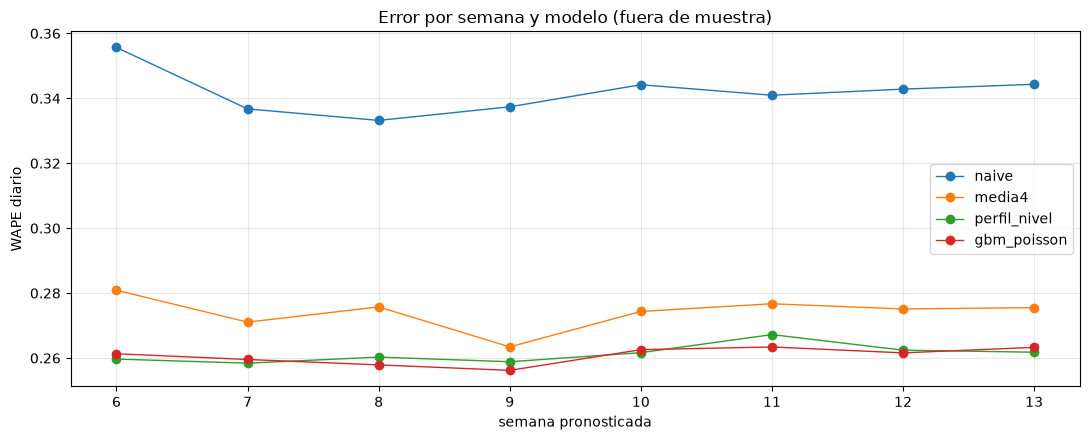

In [4]:
bt = backtest_origen_movil(panel, MODELOS_BACKTEST)
modelos = list(MODELOS_BACKTEST)

por_semana = pd.DataFrame({w: {m: wape(d["unidades_vendidas"], d[m]) for m in modelos}
                           for w, d in bt.groupby("semana")}).T
display(por_semana.round(3))

resumen = resumen_wape(bt, modelos)
resumen["mejora_vs_naive_%"] = 100 * (resumen.loc["naive", "wape_medio"] - resumen["wape_medio"]) / resumen.loc["naive", "wape_medio"]
display(resumen.round(3))

ax = por_semana.plot(marker="o", lw=1)
ax.set_ylabel("WAPE diario"); ax.set_xlabel("semana pronosticada"); ax.set_title("Error por semana y modelo (fuera de muestra)")
plt.tight_layout(); plt.show()

**Lectura del gráfico.**

- **Los cuatro modelos son estables a lo largo de las semanas:** las líneas son casi paralelas y no hay una semana en que alguno se descontrole. Eso respalda que los resultados no dependen de una semana en particular.
- **El orden se mantiene en las 8 semanas:** el naive es el peor (0.33–0.36), la media de 4 semanas queda en el medio (0.26–0.28) y el perfil × nivel y el boosting se ubican abajo, casi superpuestos (0.256–0.267).
- **El boosting y el perfil × nivel se cruzan:** en unas semanas gana uno y en otras el otro, con diferencias de milésimas. Es un empate técnico, no una ventaja de uno sobre el otro.
- **El naive es más inestable** (la semana 6 es su peor punto, 0.356): copiar la semana pasada hereda todo el ruido de esa semana. Los demás modelos promedian varias semanas y suavizan esa variación.

In [5]:
# Regla de decisión (la del EDA, H12): el modelo complejo se justifica solo si supera al más simple
# por más que la desviación entre semanas, y en la mayoría de las semanas.
simple, complejo = "media4", MODELO_FINAL
dif = resumen.loc[simple, "wape_medio"] - resumen.loc[complejo, "wape_medio"]
semanas_mejor = int((por_semana[complejo] < por_semana[simple]).sum())
umbral = resumen.loc[[simple, complejo], "desv_entre_semanas"].max()
print(f"Diferencia de WAPE ({simple} − {complejo}): {dif:.4f} | desviación entre semanas: {umbral:.4f}")
print(f"{complejo} gana en {semanas_mejor} de {len(por_semana)} semanas")
if dif > umbral and semanas_mejor > len(por_semana) / 2:
    print("→ El modelo de boosting mejora de forma consistente: se justifica su complejidad.")
else:
    print("→ La mejora no es consistente: la parsimonia favorece al modelo simple como baseline del pronóstico.")

Diferencia de WAPE (media4 − gbm_poisson): 0.0134 | desviación entre semanas: 0.0051
gbm_poisson gana en 8 de 8 semanas
→ El modelo de boosting mejora de forma consistente: se justifica su complejidad.


In [6]:
# Comparación adicional: contra la MEJOR referencia simple (no solo media4).
# La regla de arriba usa media4; aquí se repite con el modelo simple más fuerte.
simples = ["naive", "media4", "perfil_nivel"]
mejor_simple = resumen.loc[simples, "wape_medio"].idxmin()
dif2 = resumen.loc[mejor_simple, "wape_medio"] - resumen.loc[MODELO_FINAL, "wape_medio"]
gana2 = int((por_semana[MODELO_FINAL] < por_semana[mejor_simple]).sum())
umbral2 = resumen.loc[[mejor_simple, MODELO_FINAL], "desv_entre_semanas"].max()
print(f"Mejor referencia simple: {mejor_simple} (WAPE {resumen.loc[mejor_simple, 'wape_medio']:.4f})")
print(f"Diferencia ({mejor_simple} − {MODELO_FINAL}): {dif2:.4f} | desviación entre semanas: {umbral2:.4f}")
print(f"{MODELO_FINAL} gana en {gana2} de {len(por_semana)} semanas")
if dif2 > umbral2 and gana2 > len(por_semana) / 2:
    print("→ El boosting supera de forma consistente a la mejor referencia simple.")
else:
    print("→ Empate técnico con la mejor referencia simple: el boosting no se justifica por precisión.")

Mejor referencia simple: perfil_nivel (WAPE 0.2613)
Diferencia (perfil_nivel − gbm_poisson): 0.0006 | desviación entre semanas: 0.0028
gbm_poisson gana en 4 de 8 semanas
→ Empate técnico con la mejor referencia simple: el boosting no se justifica por precisión.


**Lectura.**

- **Todos los modelos mejoran al naive (WAPE 0.342)**: la media de 4 semanas lo reduce 19.8 % (0.274), y el perfil × nivel y el boosting 23.6 % y 23.7 % (ambos 0.261).
- **El boosting y el perfil × nivel empatan.** La diferencia media es de ≈0.0006 de WAPE a favor del boosting, muy por debajo de la desviación entre semanas (≈0.003), y ninguno gana de forma consistente (el boosting gana en unas semanas y pierde en otras). La complejidad extra del boosting no se paga en precisión en estos datos.
- **El boosting sí supera a la media de 4 semanas en las 8 semanas**, por 0.0134 de WAPE en promedio (más que la desviación entre semanas, 0.005).
- **Queda poco margen.** El EDA estimó un piso de error cercano a 0.25 por el ruido propio de la demanda diaria; con 0.261 estamos cerca de él, así que más modelado no daría mucha más precisión.
- El resultado fuera de muestra coincide con el del EDA (mejor boosting ≈ 0.26), lo que da confianza de que no es un artefacto del backtest.

**Decisión del modelo.** La regla de arriba solo compara contra la media de 4 semanas y dice que el boosting se justifica. Al compararlo también contra el perfil × nivel (celda anterior), el resultado es un **empate técnico**. Se mantiene el boosting con pérdida de Poisson como modelo de trabajo por tres razones: rinde igual que la mejor referencia simple, ya está integrado con la calibración de cuantiles y el optimizador, y puede incorporar variables adicionales (precio, promociones, calendario) cuando existan. Se deja constancia de que un modelo mucho más simple, el perfil × nivel, rinde lo mismo, y sería la alternativa si se prefiere explicabilidad.

## 3. Sensibilidad: pérdida e hiperparámetros

¿Importa la pérdida de Poisson frente a la cuadrática? ¿Cambian mucho los resultados con otra profundidad o número de iteraciones? Se corre el mismo backtest variando una cosa a la vez. Si los resultados quedan dentro de la desviación entre semanas, el modelo no es sensible a esas decisiones.

In [7]:
configs = {
    "Poisson (base)":        dict(),
    "Pérdida cuadrática":    dict(loss="squared_error"),
    "Profundidad 3":         dict(max_depth=3),
    "Profundidad 6":         dict(max_depth=6),
    "100 iteraciones":       dict(max_iter=100),
    "400 iteraciones":       dict(max_iter=400),
}
fabricas = {nombre: (lambda kw=kw: ModeloPoissonGBM(**kw)) for nombre, kw in configs.items()}
bt_cfg = backtest_origen_movil(panel, fabricas)
sens = resumen_wape(bt_cfg, list(configs))
sens["frente_a_base_%"] = 100 * (sens["wape_medio"] / sens.loc["Poisson (base)", "wape_medio"] - 1)
display(sens.round(4))
print("Desviación entre semanas del modelo base:", round(sens.loc["Poisson (base)", "desv_entre_semanas"], 4))

,wape_medio,desv_entre_semanas,frente_a_base_%
Poisson (base),0.261,0.003,0.000
Pérdida cuadrática,0.262,0.002,0.299
Profundidad 3,0.261,0.003,0.055
Profundidad 6,0.262,0.003,0.521
100 iteraciones,0.261,0.003,-0.086
400 iteraciones,0.262,0.003,0.507


Desviación entre semanas del modelo base: 0.0026


**Lectura.** Todas las configuraciones quedan entre 0.261 y 0.262 de WAPE, dentro del ruido entre semanas (≈0.003); la diferencia máxima respecto de la base es 0.5 %. El modelo **no es sensible** a la pérdida, a la profundidad ni al número de iteraciones. La pérdida de Poisson se mantiene por coherencia con la naturaleza de los datos (conteos no negativos), no porque aporte una mejora medible frente a la cuadrática (0.3 %).

## 4. ¿Dónde falla el pronóstico?

El WAPE global puede esconder grupos mal pronosticados. Se revisa por día de la semana, por producto y por nivel de venta, junto con el **sesgo** (suma de pronósticos ÷ suma de ventas: 1.00 es sin sesgo; menos de 1 es subestimar la demanda).

In [8]:
def tabla_error(df, por):
    g = df.groupby(por)
    out = pd.DataFrame({
        "wape": g.apply(lambda d: wape(d["unidades_vendidas"], d[MODELO_FINAL])),
        "sesgo": g.apply(lambda d: d[MODELO_FINAL].sum() / d["unidades_vendidas"].sum()),
        "ventas": g["unidades_vendidas"].sum(),
    })
    return out

nombres = datos.catalogo.set_index("id_producto")["nombre"]
bt_ = bt.assign(producto=bt["id_producto"].map(nombres),
                dia=bt["dow"].map(dict(enumerate(["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]))))
nivel = bt_.groupby(["id_tienda", "id_producto"])["unidades_vendidas"].transform("mean")
bt_["volumen"] = pd.qcut(nivel, 3, labels=["bajo", "medio", "alto"])
for por in ["dia", "producto", "volumen"]:
    print(f"\nPor {por}:"); display(tabla_error(bt_, por).round(3))


Por dia:


,wape,sesgo,ventas
dia,,,
dom,0.244,0.987,"21,162.000"
jue,0.285,1.006,"13,896.000"
lun,0.274,1.002,"14,043.000"
mar,0.288,1.006,"13,978.000"
mié,0.275,1.006,"13,818.000"
sáb,0.243,1.008,"20,794.000"
vie,0.242,0.993,"21,246.000"



Por producto:


,wape,sesgo,ventas
producto,,,
Buñuelo,0.234,0.995,"20,058.000"
Café con Leche,0.291,1.000,"12,782.000"
Cappuccino,0.271,0.991,"13,186.000"
Croissant,0.229,0.996,"18,193.000"
Jugo de Naranja,0.267,1.016,"18,232.000"
Pan de Bono,0.330,0.998,"7,867.000"
Pastel de Pollo,0.232,0.999,"19,347.000"
Tinto,0.312,1.005,"9,272.000"



Por volumen:


,wape,sesgo,ventas
volumen,,,
bajo,0.342,1.024,"22,164.000"
medio,0.276,1.016,"37,291.000"
alto,0.221,0.981,"59,482.000"


**Lectura.**

- **El sesgo es casi nulo** en todos los cortes (entre 0.98 y 1.02). Hay un patrón leve: se sobrepronostica 2.4 % en los SKU-tienda de volumen bajo y se subpronostica 1.9 % en los de volumen alto, típico de un modelo que se acerca a la media.
- **El error relativo baja con el volumen:** 0.342 en volumen bajo, 0.276 en medio y 0.221 en alto. Es lo esperado cuando la demanda son conteos: con pocas unidades el ruido pesa más.
- **Por producto**, los peores son Pan de Bono (0.330) y Tinto (0.312), que son justamente los de menos ventas en las semanas de prueba (7,867 y 9,272 unidades); los mejores son Croissant, Pastel de Pollo y Buñuelo (≈0.23), de más volumen. Es el mismo efecto de volumen, no una falla del modelo en esos productos.
- **Por día**, lunes a jueves tienen más error (0.27–0.29) que viernes a domingo (0.24), porque en esos días se vende menos. 
- **Implicación para el pedido:** el error se concentra en los SKU-tienda de poco volumen, y por eso la calibración de cuantiles se hace por terciles de volumen: ahí el colchón debe ser relativamente más ancho.

### Pronóstico frente a ventas reales (backtest fuera de muestra)

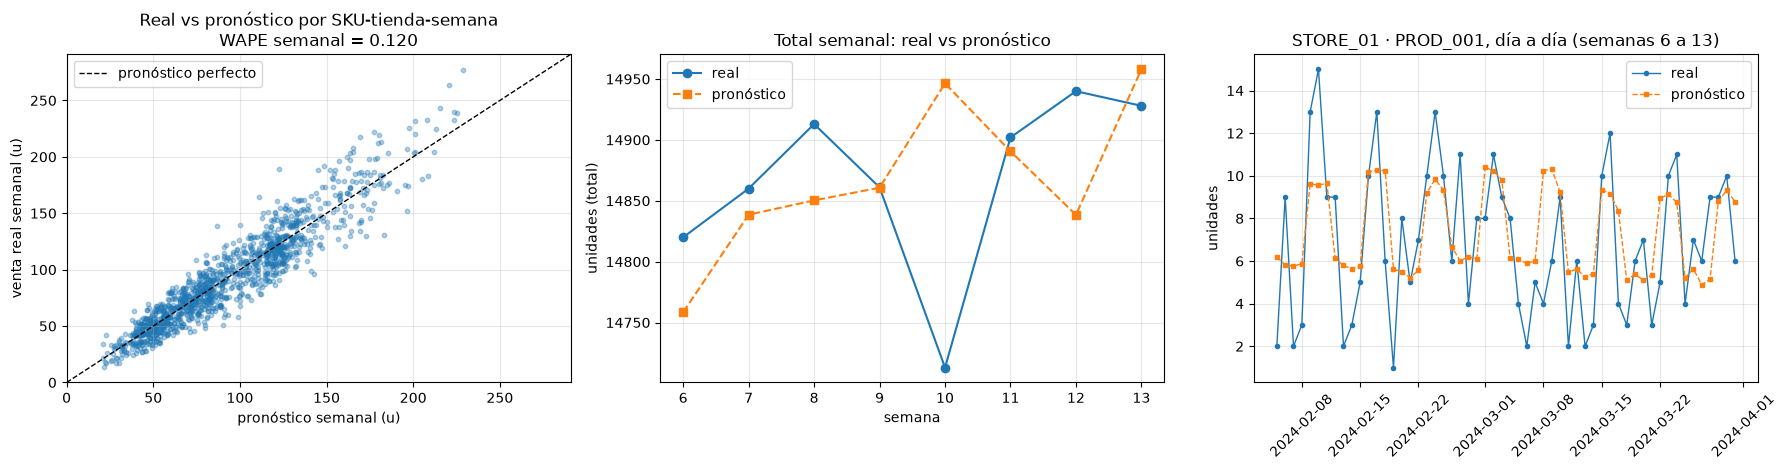

In [14]:
semanal = agregar_semanal(bt, [MODELO_FINAL])
real, pron = semanal["unidades_vendidas"], semanal[MODELO_FINAL]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# 1) Real vs pronóstico: cada punto es un SKU-tienda en una semana de prueba
ax = axes[0]
ax.scatter(pron, real, s=10, alpha=0.35)
tope = max(pron.max(), real.max()) * 1.05
ax.plot([0, tope], [0, tope], "k--", lw=1, label="pronóstico perfecto")
ax.set_xlim(0, tope); ax.set_ylim(0, tope)
ax.set_xlabel("pronóstico semanal (u)"); ax.set_ylabel("venta real semanal (u)")
ax.set_title(f"Real vs pronóstico por SKU-tienda-semana\nWAPE semanal = {wape(real, pron):.3f}")
ax.legend()

# 2) Total de todas las tiendas y productos, por semana
ax = axes[1]
tot = semanal.groupby("semana")[["unidades_vendidas", MODELO_FINAL]].sum()
ax.plot(tot.index, tot["unidades_vendidas"], "o-", label="real")
ax.plot(tot.index, tot[MODELO_FINAL], "s--", label="pronóstico")
ax.set_xlabel("semana"); ax.set_ylabel("unidades (total)")
ax.set_title("Total semanal: real vs pronóstico"); ax.legend()

# 3) Un SKU-tienda, día a día (cambia tienda y producto para ver otros)
tienda, producto = "STORE_01", "PROD_001"
ax = axes[2]
d = bt[(bt["id_tienda"] == tienda) & (bt["id_producto"] == producto)].sort_values("fecha")
ax.plot(d["fecha"], d["unidades_vendidas"], "o-", ms=3, lw=1, label="real")
ax.plot(d["fecha"], d[MODELO_FINAL], "s--", ms=3, lw=1, label="pronóstico")
ax.set_title(f"{tienda} · {producto}, día a día (semanas 6 a 13)")
ax.set_ylabel("unidades"); ax.legend(); ax.tick_params(axis="x", rotation=45)

plt.tight_layout(); plt.show()

**Lectura.**

- **Por SKU-tienda y semana (izquierda).** Los puntos se agrupan alrededor de la línea de pronóstico perfecto, sin una desviación sistemática hacia arriba o hacia abajo. El WAPE semanal es 0.120, bastante menor que el diario (0.261): al sumar siete días, los errores de un día se compensan con los de otro, y lo que queda es el ruido propio de la demanda semanal. La dispersión crece en unidades con el volumen, pero es relativamente menor en los SKU de más venta, como ya mostró la sección 4.
- **Total semanal (centro).** El total pronosticado sigue de cerca al real: las diferencias van de unas decenas de unidades hasta ≈230 (semana 10, ≈1.6 %). No queda siempre por encima ni por debajo, es decir, no hay sesgo. El eje está ampliado (de 14,700 a 14,950 unidades); el total semanal es muy estable, y las diferencias pequeñas se ven grandes por la escala.
- **Un SKU-tienda, día a día (derecha).** La venta real de STORE_01 · PROD_001 oscila mucho (entre 1 y 15 unidades al día, con un promedio cercano a 6), mientras que el pronóstico sigue el patrón semanal: bajo de lunes a jueves y alto de viernes a domingo. El modelo no puede predecir los picos y caídas de un día concreto; esa variación es ruido de conteos pequeños y no se puede reducir con más modelado. Por eso el pedido se decide con la demanda de la semana y con cuantiles, no con el pronóstico de un día.
- **Qué se concluye.** El modelo captura el nivel y el patrón semanal de cada SKU-tienda sin sesgo visible, y su error es el esperable por la variabilidad natural de la demanda; no se observan señales de sobreajuste (el error es similar en las 8 semanas de prueba).

## 5. Cuantiles calibrados

El pedido necesita un cuantil de la demanda (no solo la media). En lugar de suponer una distribución, se usa la distribución empírica de la *venta relativa semanal* (real ÷ pronóstico) del backtest, por terciles de volumen. Para comprobar que funciona, cada semana se calibra **solo con las semanas anteriores** y se mide cuántas veces la demanda real quedó por debajo del cuantil pronosticado: debería coincidir con el nivel nominal.

,cobertura_observada,error_de_cobertura
nivel_nominal,,
0.500,0.516,0.016
0.800,0.805,0.005
0.900,0.905,0.005
0.950,0.948,-0.002


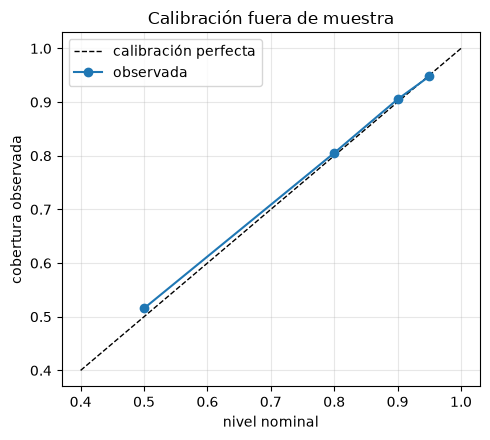

In [9]:
semanal = agregar_semanal(bt, [MODELO_FINAL])
cob = cobertura_secuencial(semanal, MODELO_FINAL)
cob["error_de_cobertura"] = cob["cobertura_observada"] - cob.index
display(cob.round(3))

fig, ax = plt.subplots(figsize=(5, 4.5))
ax.plot([0.4, 1], [0.4, 1], "k--", lw=1, label="calibración perfecta")
ax.plot(cob.index, cob["cobertura_observada"], "o-", label="observada")
ax.set_xlabel("nivel nominal"); ax.set_ylabel("cobertura observada"); ax.legend(); ax.set_title("Calibración fuera de muestra")
plt.tight_layout(); plt.show()

**Lectura.** La cobertura observada fuera de muestra es 0.516, 0.805, 0.905 y 0.948 para los niveles nominales 0.5, 0.8, 0.9 y 0.95; el error de cobertura es como máximo 1.6 puntos porcentuales y de 0.5 puntos en los niveles que importan para el pedido (0.8 a 0.95). Es decir, **los cuantiles están bien calibrados**: pedir el cuantil 90 % cubre la demanda cerca del 90 % de las semanas, calibrando cada semana solo con las anteriores.

Esto vale mientras el comportamiento futuro se parezca al del backtest; con 13 semanas de historia no se observó estacionalidad anual ni eventos de calendario (ver limitaciones).

In [10]:
# Ancho relativo del intervalo P10–P90 según el volumen del SKU-tienda
cal = CalibradorCuantiles().ajustar(semanal["unidades_vendidas"], semanal[MODELO_FINAL])
pron = semanal[MODELO_FINAL].to_numpy()
p10, p90 = (cal.cuantil_demanda(np.full(len(pron), t), pron) for t in (0.1, 0.9))
ancho = pd.DataFrame({"volumen": pd.qcut(pron, 3, labels=["bajo", "medio", "alto"]), "ancho_relativo": (p90 - p10) / pron})
display(ancho.groupby("volumen")["ancho_relativo"].describe()[["mean", "min", "max"]].round(3))

,mean,min,max
volumen,,,
bajo,0.485,0.485,0.485
medio,0.413,0.413,0.413
alto,0.335,0.335,0.335


**Lectura del ancho.** El intervalo P10–P90 es ≈ 0.49 veces el pronóstico para volumen bajo, 0.41 para medio y 0.34 para alto (aproximadamente ±24 %, ±21 % y ±17 % alrededor del pronóstico). Más incertidumbre relativa donde hay menos ventas. Los valores mínimo y máximo coinciden dentro de cada grupo porque el multiplicador se calcula por tercil de volumen y no por SKU; es una simplificación que no distingue la volatilidad propia de cada SKU-tienda.

## 6. Pronóstico de la semana 1–7 de abril de 2024

Se entrena con las 13 semanas observadas y se pronostica la semana siguiente. La media sale de sumar el pronóstico diario; P10, P50 y P90 salen de la calibración anterior. El pronóstico no se puede comparar con ventas reales (la semana no se ha observado): la confianza en él viene del backtest.

,id_tienda,id_producto,nombre,pronostico_media,p10,p50,p90
0,STORE_01,PROD_001,Tinto,48.650,36.660,49.130,60.270
1,STORE_01,PROD_002,Café con Leche,62.910,47.410,63.540,77.940
2,STORE_01,PROD_003,Cappuccino,63.180,47.620,63.810,78.280
3,STORE_01,PROD_004,Pan de Bono,47.070,35.470,47.540,58.320
4,STORE_01,PROD_005,Buñuelo,76.700,59.900,76.000,91.560
5,STORE_01,PROD_006,Croissant,79.010,61.700,78.290,94.320
6,STORE_01,PROD_007,Pastel de Pollo,77.210,60.300,76.510,92.180
7,STORE_01,PROD_008,Jugo de Naranja,72.010,56.240,71.360,85.970
8,STORE_02,PROD_001,Tinto,73.180,57.150,72.520,87.360
9,STORE_02,PROD_002,Café con Leche,92.160,71.970,91.320,110.020


Demanda semanal total pronosticada: 14,981 u
Ventas de la última semana observada:  14,928 u


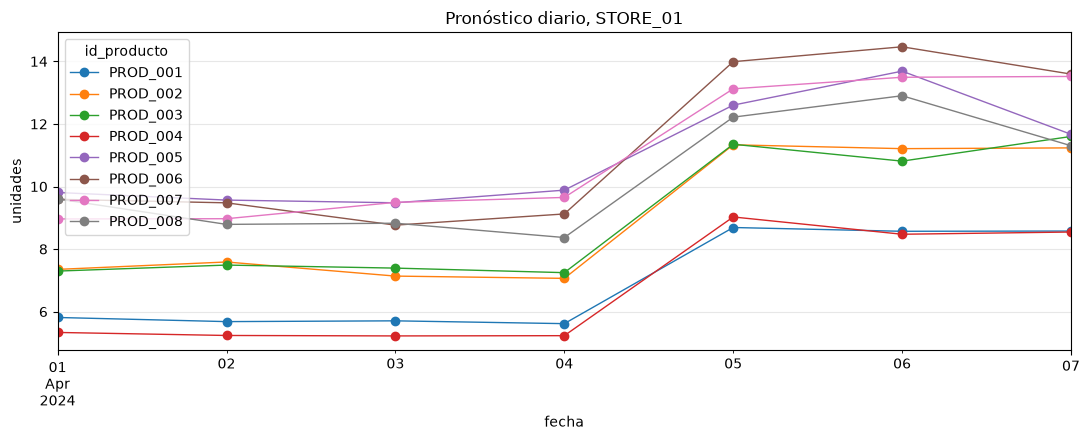

In [11]:
diario, semanal_fut = pronosticar_semana(panel, datos, cal)
display(semanal_fut.head(10))
print(f"Demanda semanal total pronosticada: {semanal_fut['pronostico_media'].sum():,.0f} u")
print(f"Ventas de la última semana observada:  {historia[historia['semana'] == historia['semana'].max()]['unidades_vendidas'].sum():,.0f} u")

tienda = semanal_fut["id_tienda"].iloc[0]
ej = diario[diario["id_tienda"] == tienda].pivot_table(index="fecha", columns="id_producto", values="pronostico")
ax = ej.plot(marker="o", lw=1); ax.set_title(f"Pronóstico diario, {tienda}"); ax.set_ylabel("unidades"); plt.tight_layout(); plt.show()

**Lectura.** La demanda total pronosticada para la semana del 1 al 7 de abril es 14,981 unidades, frente a 14,928 vendidas en la última semana observada (+0.4 %): el pronóstico es coherente con el nivel reciente, sin saltos. Cada SKU-tienda trae su media y sus cuantiles P10, P50 y P90; por ejemplo, el Tinto de STORE_01 tiene media 48.7 y un intervalo P10–P90 de 36.7 a 60.3 unidades.

In [12]:
carpeta = RAIZ / "outputs"; carpeta.mkdir(exist_ok=True)
semanal_fut.to_csv(carpeta / "pronostico_semanal.csv", index=False)
print("Guardado:", carpeta / "pronostico_semanal.csv")

Guardado: /Users/adriananivia/Downloads/repo/outputs/pronostico_semanal.csv


## 7. Pruebas de mejora

Con los datos disponibles se pueden probar tres ideas que suelen mejorar un pronóstico. Se evalúan con el mismo backtest (semanas 6 a 13) y se comparan contra el modelo base:

1. **Ensamble:** promedio del boosting y del perfil × nivel (dos modelos que se equivocan de forma distinta).
2. **Modelo por segmento de volumen:** un boosting para los SKU-tienda de poca venta, otro para los de venta media y otro para los de mucha venta.
3. **Variables adicionales:** tamaño y ciudad de la tienda, y la tendencia reciente (venta de la última semana ÷ promedio de 4 semanas).

Una mejora solo cuenta si supera al base por más que la desviación entre semanas y en la mayoría de las semanas, igual que la regla de la sección 2.

In [13]:
from tostao_abastecimiento.features import agregar_variables_extra
from tostao_abastecimiento.config import COLUMNAS_EXTRA
from tostao_abastecimiento.models import ModeloPorSegmento, PromedioModelos

panel_x = agregar_variables_extra(panel, datos)
experimentos = {
    "base (boosting Poisson)":               ModeloPoissonGBM,
    "ensamble (boosting + perfil×nivel)":    lambda: PromedioModelos([ModeloPoissonGBM, PerfilPorNivel]),
    "boosting por segmento de volumen":      lambda: ModeloPorSegmento(ModeloPoissonGBM),
    "boosting + tamaño, ciudad, tendencia":  lambda: ModeloPoissonGBM(columnas=list(COLUMNAS_MODELO) + list(COLUMNAS_EXTRA)),
}
bt_x = backtest_origen_movil(panel_x, {"perfil_nivel (referencia)": PerfilPorNivel, **experimentos})
cols_x = list(bt_x.columns[-(len(experimentos) + 1):])
res_x = resumen_wape(bt_x, cols_x)
por_sem_x = pd.DataFrame({w: {c: wape(d["unidades_vendidas"], d[c]) for c in cols_x} for w, d in bt_x.groupby("semana")}).T
base = "base (boosting Poisson)"
res_x["mejora_vs_base_%"] = 100 * (res_x.loc[base, "wape_medio"] - res_x["wape_medio"]) / res_x.loc[base, "wape_medio"]
res_x["semanas_que_gana_al_base"] = [(por_sem_x[c] < por_sem_x[base]).sum() for c in res_x.index]
display(res_x.round(4))

for c in experimentos:
    if c == base:
        continue
    dif = res_x.loc[base, "wape_medio"] - res_x.loc[c, "wape_medio"]
    umbral = res_x.loc[[base, c], "desv_entre_semanas"].max()
    ok = dif > umbral and res_x.loc[c, "semanas_que_gana_al_base"] > len(por_sem_x) / 2
    print(f"{c}: mejora {dif:+.4f} de WAPE (umbral {umbral:.4f}) → {'MEJORA consistente' if ok else 'sin mejora consistente'}")

,wape_medio,desv_entre_semanas,mejora_vs_base_%,semanas_que_gana_al_base
perfil_nivel (referencia),0.261,0.003,-0.216,4
base (boosting Poisson),0.261,0.003,0.000,0
ensamble (boosting + perfil×nivel),0.259,0.003,0.740,8
boosting por segmento de volumen,0.264,0.002,-1.348,1
"boosting + tamaño, ciudad, tendencia",0.261,0.003,-0.174,1


ensamble (boosting + perfil×nivel): mejora +0.0019 de WAPE (umbral 0.0026) → sin mejora consistente
boosting por segmento de volumen: mejora -0.0035 de WAPE (umbral 0.0026) → sin mejora consistente
boosting + tamaño, ciudad, tendencia: mejora -0.0005 de WAPE (umbral 0.0026) → sin mejora consistente


**Lectura.** Ninguna de las tres ideas cumple la regla de mejora (superar al modelo base por más que la desviación entre semanas, ≈0.003, y en la mayoría de las semanas).

- **Ensamble (boosting + perfil × nivel):** es el único que mejora: WAPE 0.259 frente a 0.261, es decir, 0.0019 menos (una reducción relativa del error de 0.7 %), y gana al base en las 8 semanas. Aun así, la mejora media queda por debajo del umbral de ruido (0.0026), así que es una ganancia pequeña, aunque constante. Es la mejora más barata de incorporar si se busca precisión adicional, pero no cambia la decisión: se mantiene el modelo base por simplicidad.
- **Modelo por segmento de volumen:** empeora (WAPE 0.264 frente a 0.261, el error sube 1.3 % en términos relativos) y solo gana en 1 de 8 semanas. Dividir los datos en tres grupos deja menos filas para entrenar cada modelo, y el modelo global ya incorpora el volumen mediante el nivel reciente de cada SKU-tienda. Con más historia podría cambiar.
- **Variables adicionales (tamaño, ciudad, tendencia):** sin efecto (WAPE 0.261, igual que el base). El tamaño y la ciudad ya están representados por la tienda, y la tendencia ya está contenida en las medias móviles de 7 y 28 días.
- **Referencia (perfil × nivel):** empata con el base (gana en 4 de 8 semanas), como ya se había visto en la sección 2.

**Qué se concluye.** Con estos datos y esta historia, el error no baja con más complejidad: está cerca del piso que fija el ruido propio de la demanda (≈0.25 según el EDA). Las mejoras que probablemente sí moverían el resultado requieren información que hoy no existe: más historia, calendario, precios y promociones (ver sección 8).

## 8. Recomendaciones para mejorar el pronóstico

Lo que haría, en orden de impacto esperado:

1. **Más historia (uno o dos años).** Con 13 semanas no se aprende estacionalidad anual ni el efecto de temporadas como diciembre. Es la limitación más importante.
2. **Variables de calendario:** festivos y puentes, quincenas de pago, Semana Santa, fechas comerciales. Sin ellas, el modelo reacciona tarde a los picos y no puede anticipar caídas como la de la semana 10, que no se explican con los datos disponibles.
3. **Precios y promociones reales.** Hoy no hay variación de precio medible ni calendario promocional; con ellos se podría estimar elasticidad y evitar que una promoción pase por "demanda normal".
4. **Historial diario de stock y quiebres.** Permite detectar demanda censurada (ventas que no ocurrieron por falta de producto) y corregirla; hoy no se detecta ninguna, pero con una foto de stock no se puede descartar.
5. **Tratamiento por segmento de ventas.** Los SKU-tienda de poca venta tienen el mayor error relativo. Un modelo separado por segmento de volumen no mejoró con 13 semanas (sección 7: dividir los datos deja pocas filas por grupo), así que con esta historia conviene un modelo global; con más historia vale la pena repetir la prueba. Para los SKU de muy poca venta o intermitentes, se pueden usar métodos específicos de demanda intermitente (Croston, TSB).
6. **Ensamble de modelos.** Promediar el boosting con el perfil × nivel redujo el error 0.7 % (WAPE 0.259 frente a 0.261) y ganó en las 8 semanas; la mejora es pequeña, pero constante y de bajo costo. Es la primera opción a incorporar si se busca precisión adicional.
7. **Modelos probabilísticos directos.** Regresión por cuantiles o distribuciones para conteos (Poisson, binomial negativa) en lugar de calibrar el error encima del pronóstico, evaluados con la pérdida de cuantil.
8. **Pronóstico jerárquico.** Pronosticar por categoría, tienda y total, y reconciliar con el pronóstico por SKU-tienda; ayuda a los SKU con poca historia.
9. **Modelos por serie (ETS, ARIMA) como referencia**, cuando haya historia suficiente por serie; con 13 semanas tendrían pocos datos.
10. **Variables externas:** clima, eventos, competencia. El índice de precio de la competencia de la carpeta 03 no tiene diccionario y mostró correlación cercana a cero.
11. **Monitoreo en producción:** reentrenar cada semana, vigilar sesgo y cobertura por segmento, y alertar cuando se degraden.

## 9. Conclusiones de la experimentación

- **Modelo.** Todos los modelos mejoran al naive (WAPE 0.342) entre 20 % y 24 %. El boosting con pérdida de Poisson (0.261) supera a la media de 4 semanas en las 8 semanas, pero **empata con el perfil × nivel (0.261)**. Se usa el boosting como modelo de trabajo, dejando constancia de que una alternativa más simple rinde igual. Agregado por semana, el WAPE por SKU-tienda baja a 0.120, porque los errores diarios se compensan dentro de la semana.
- **Sensibilidad.** Ninguna variación de pérdida o hiperparámetros cambia el WAPE más de 0.5 %: el resultado no depende de esas decisiones.
- **Dónde falla.** El error relativo es mayor en SKU-tienda de poco volumen (0.342 frente a 0.221 en volumen alto), lo que coincide con el ruido propio de conteos pequeños; el sesgo es casi nulo. La semana 10 quedó ≈1.6 % por debajo del pronóstico en total, con la diferencia repartida entre productos y tiendas y concentrada en tres días; es compatible con la variabilidad natural y no se atribuye a un evento concreto.
- **Incertidumbre.** La cobertura fuera de muestra (0.516, 0.805, 0.905, 0.948) coincide con el nivel nominal (0.5, 0.8, 0.9, 0.95), con error máximo de 1.6 puntos porcentuales.
- **Pronóstico.** 14,981 unidades para la semana del 1 al 7 de abril (+0.4 % frente a la última semana observada), con P10, P50 y P90 por SKU-tienda en `outputs/pronostico_semanal.csv`.
- **Pruebas de mejora.** Ensamble, modelo por segmento y variables adicionales (sección 7): ninguna supera la regla de mejora. El ensamble gana en las 8 semanas pero reduce el error solo 0.7 % en términos relativos (WAPE 0.259 frente a 0.261); el modelo por segmento empeora, y las variables extra no aportan. Se mantiene el modelo base.
- **Límites.** Solo hay 13 semanas de historia: no se observan estacionalidad anual ni efectos de calendario (festivos, temporadas). La calibración agrupa por volumen y no por SKU. No se probaron modelos por serie (ARIMA, ETS), que con tan poca historia por serie tendrían pocos datos. La comparación de métodos de incertidumbre con la pérdida de cuantil se hace en el notebook 03.
- **Siguiente paso:** `03_optimizacion_costos.ipynb` usa estos pronósticos y cuantiles para calcular el pedido y medir su valor en costos.